In [113]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,precision_score,f1_score,recall_score

pd.set_option('display.max_columns',None)

In [114]:
data_path='/content/sample_data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(data_path)

In [115]:
df.shape

(7043, 21)

In [116]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [117]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [118]:
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [119]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [120]:
df.duplicated().sum()

np.int64(0)

In [121]:
df['SeniorCitizen'].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


In [122]:
cat_cols=df.select_dtypes(include='object').columns
for col in df.columns:
  print(f'{col} --> {df[col].unique()}')

customerID --> ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender --> ['Female' 'Male']
SeniorCitizen --> [0 1]
Partner --> ['Yes' 'No']
Dependents --> ['No' 'Yes']
tenure --> [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService --> ['No' 'Yes']
MultipleLines --> ['No phone service' 'No' 'Yes']
InternetService --> ['DSL' 'Fiber optic' 'No']
OnlineSecurity --> ['No' 'Yes' 'No internet service']
OnlineBackup --> ['Yes' 'No' 'No internet service']
DeviceProtection --> ['No' 'Yes' 'No internet service']
TechSupport --> ['No' 'Yes' 'No internet service']
StreamingTV --> ['No' 'Yes' 'No internet service']
StreamingMovies --> ['No' 'Yes' 'No internet service']
Contract --> ['Month-to-month' 'One year' 'Two year']
PaperlessBilling --> ['Yes' 'No']
PaymentMethod --> ['Elect

In [123]:
(df['TotalCharges']==' ').sum()

np.int64(11)

In [124]:
df['TotalCharges']=df['TotalCharges'].replace(' ',np.nan)

In [125]:
df['TotalCharges']=df['TotalCharges'].astype(float)


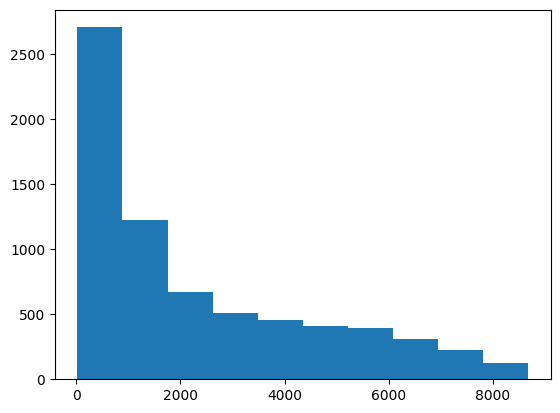

In [126]:
plt.hist(df['TotalCharges'])
plt.show()

In [127]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#Train test split

In [129]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [130]:
X,y = df.drop(['customerID','Churn'],axis=1),df['Churn']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [131]:
median_value = X_train['TotalCharges'].median()
X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median_value)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(median_value)

In [132]:
scale_cols=['MonthlyCharges','TotalCharges','tenure']

In [133]:
scaler = StandardScaler()

X_train_scale=pd.DataFrame(
  scaler.fit_transform(X_train[scale_cols]),
  columns=scale_cols,
  index=X_train.index
)
X_test_scale=pd.DataFrame(
  scaler.transform(X_test[scale_cols]),
  columns=scale_cols,
  index=X_test.index
)

In [134]:
cat_cols=X_train.select_dtypes(include='object').columns
one_hot_encoder=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X_train_encode=one_hot_encoder.fit_transform(X_train[cat_cols])
X_test_encode=one_hot_encoder.transform(X_test[cat_cols])

column_names=one_hot_encoder.get_feature_names_out(cat_cols)

X_train_encode=pd.DataFrame(
    X_train_encode,
    columns=column_names,
    index=X_train.index
)

X_test_encode=pd.DataFrame(
    X_test_encode,
    columns=column_names,
    index=X_test.index
)

In [135]:
X_train_final=pd.concat([X_train_scale,X_train_encode,X_train['SeniorCitizen']],axis=1)
X_test_final=pd.concat([X_test_scale,X_test_encode,X_test['SeniorCitizen']],axis=1)


In [136]:
label_encoder=LabelEncoder()
y_train_final=pd.Series(label_encoder.fit_transform(y_train),index=y_train.index)
y_test_final=pd.Series(label_encoder.transform(y_test),index=y_test.index)

In [137]:
smote = SMOTE(random_state=42)
X_train_balanced,y_train_balanced = smote.fit_resample(X_train_final,y_train_final)

In [138]:
y_train_balanced.value_counts()

,count
0,4139
1,4139


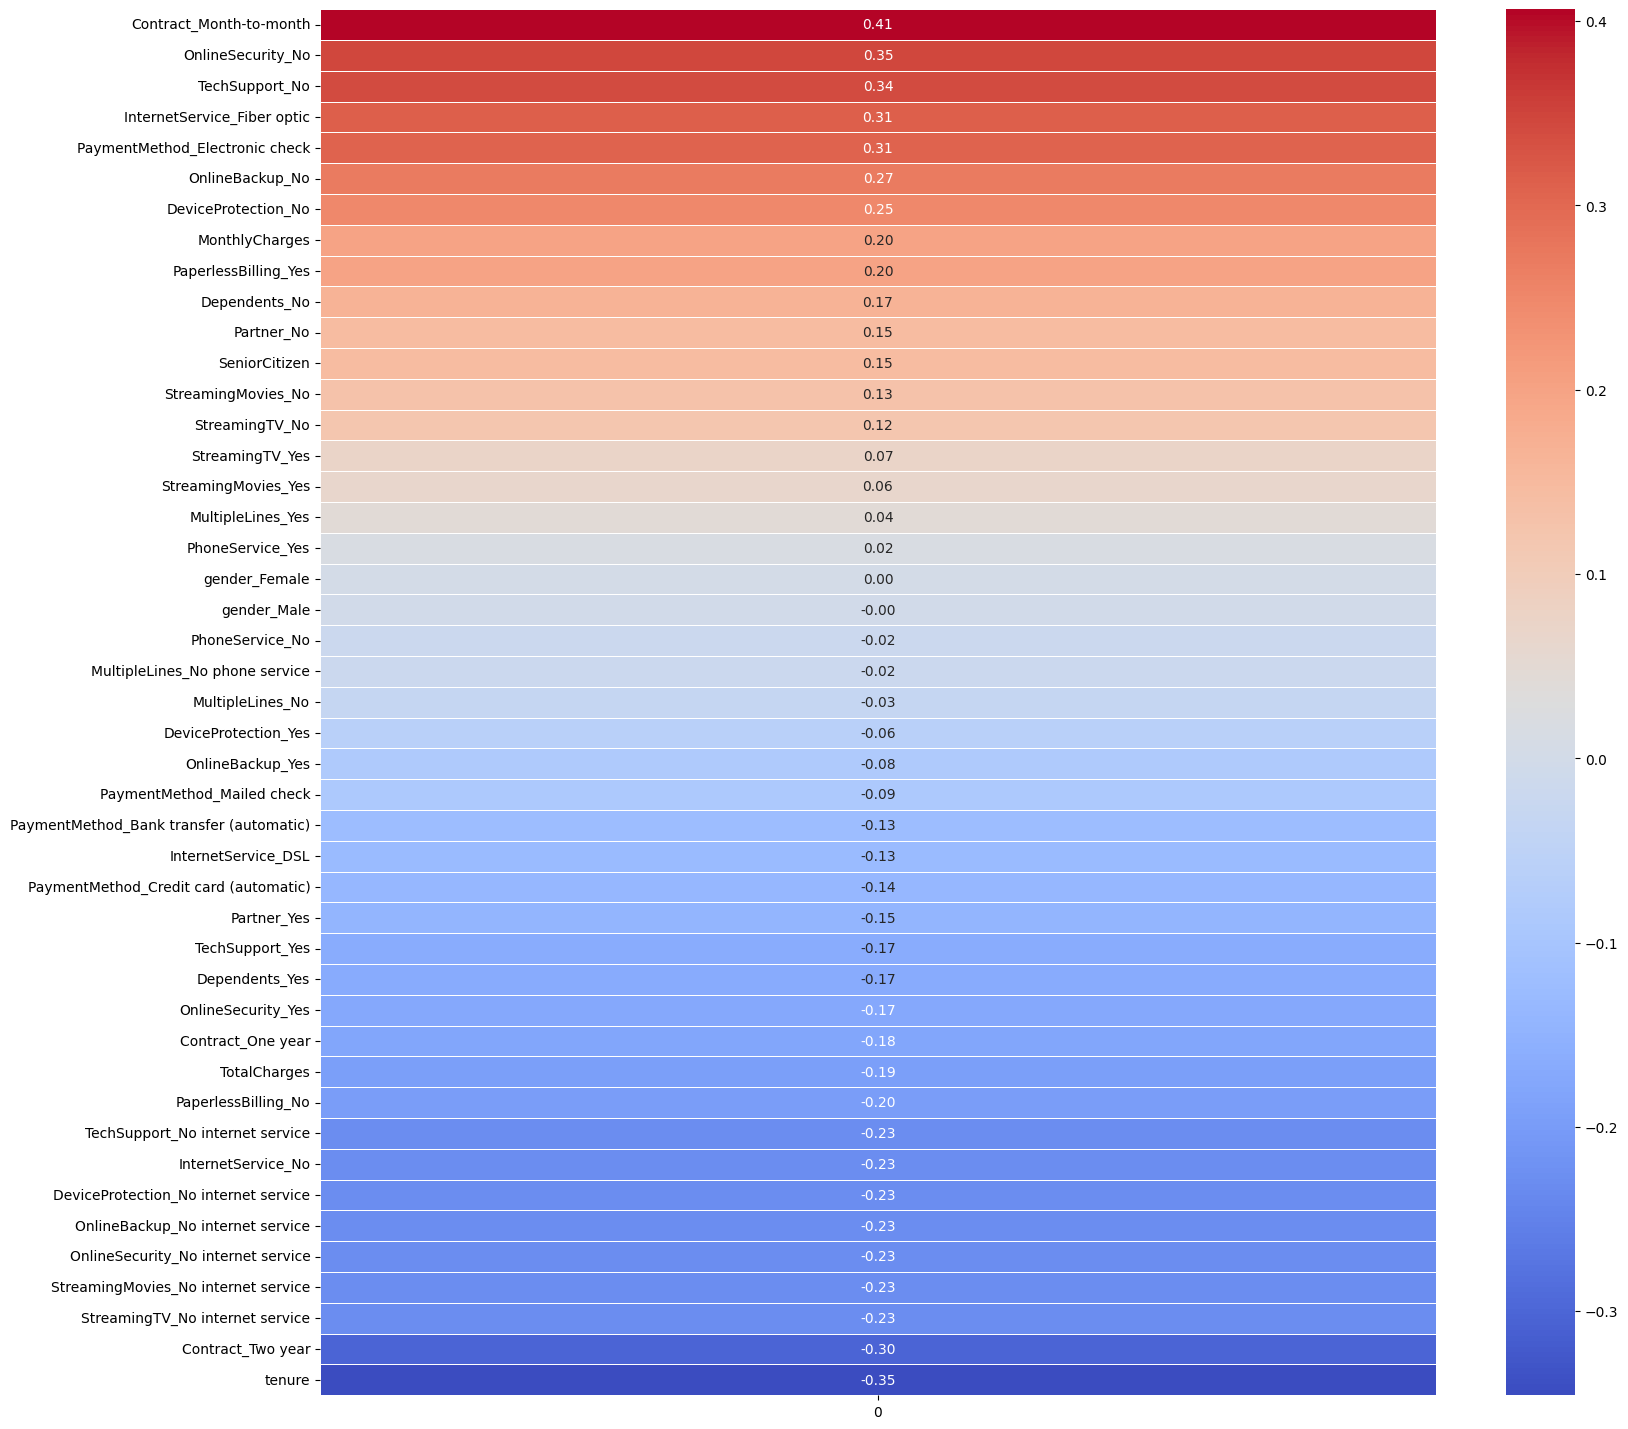

In [139]:
corr=X_train_final.corrwith(y_train_final).sort_values(ascending=False).to_frame()

plt.figure(figsize=(18,18))
sns.heatmap(corr,annot=True,linewidth=0.5,fmt='.2f',cmap='coolwarm')
plt.show()

In [140]:
X_train.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

In [141]:
selected_cols=['OnlineBackup_No','tenure', 'Contract_Month-to-month']

In [142]:
X_train_selected=X_train_balanced[selected_cols]
X_test_selected=X_test_final[selected_cols]


Accuracy Score: 0.6706884315117104
Confusion Matrix
[[625 410]
 [ 54 320]]
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.60      0.73      1035
           1       0.44      0.86      0.58       374

    accuracy                           0.67      1409
   macro avg       0.68      0.73      0.65      1409
weighted avg       0.79      0.67      0.69      1409



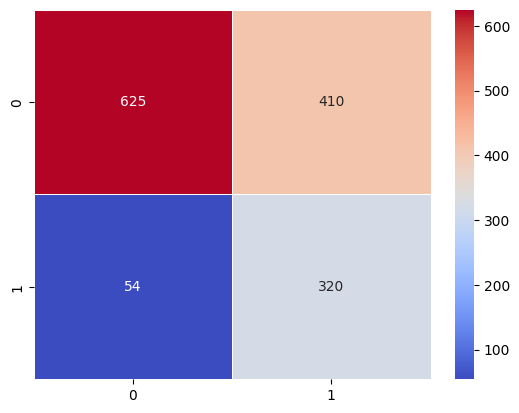

In [143]:
log_reg=LogisticRegression()
log_reg.fit(X_train_selected,y_train_balanced)
log_reg_pred=log_reg.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, log_reg_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, log_reg_pred))

print('Classification Report')
print(classification_report(y_test_final, log_reg_pred))

sns.heatmap(
    confusion_matrix(y_test_final, log_reg_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

Accuracy Score: 0.7288857345635202
Confusion Matrix
[[889 146]
 [236 138]]
Classification Report
              precision    recall  f1-score   support

           0       0.79      0.86      0.82      1035
           1       0.49      0.37      0.42       374

    accuracy                           0.73      1409
   macro avg       0.64      0.61      0.62      1409
weighted avg       0.71      0.73      0.72      1409



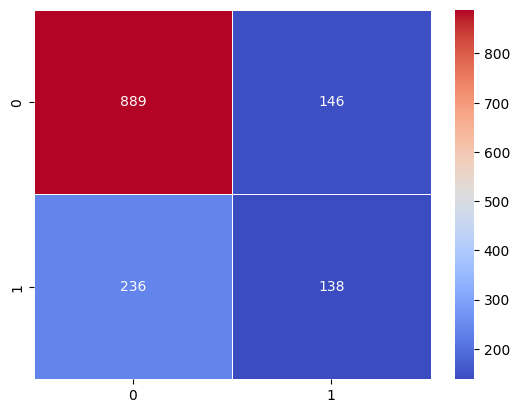

In [144]:
knn = KNeighborsClassifier(n_neighbors=17)
knn.fit(X_train_selected,y_train_balanced)
knn_pred=knn.predict(X_test_selected)

print('Accuracy Score:', accuracy_score(y_test_final, knn_pred))

print('Confusion Matrix')
print(confusion_matrix(y_test_final, knn_pred))

print('Classification Report')
print(classification_report(y_test_final, knn_pred))

sns.heatmap(
    confusion_matrix(y_test_final, knn_pred),
    annot=True,
    fmt='d',
    linewidths=0.5,
    cmap='coolwarm'
)
plt.show()

In [145]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(knn_pred).value_counts())

Actual values:
0    1035
1     374
Name: count, dtype: int64
Predicted values:
0    1125
1     284
Name: count, dtype: int64


In [146]:
print(label_encoder.classes_)

['No' 'Yes']


In [147]:
print("Actual values:")
print(y_test_final.value_counts())

print("Predicted values:")
print(pd.Series(log_reg_pred).value_counts())

Actual values:
0    1035
1     374
Name: count, dtype: int64
Predicted values:
1    730
0    679
Name: count, dtype: int64


In [148]:
# Get probability of Churn (class 1)
y_prob = log_reg.predict_proba(X_test_selected)[:, 1]

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print("Accuracy:", accuracy_score(y_test_final, y_pred_threshold))
    print("Precision:", precision_score(y_test_final, y_pred_threshold))
    print("Recall:", recall_score(y_test_final, y_pred_threshold))
    print("F1 Score:", f1_score(y_test_final, y_pred_threshold))


Threshold: 0.3
Accuracy: 0.6501064584811923
Precision: 0.4240102171136654
Recall: 0.8877005347593583
F1 Score: 0.5738980121002593

Threshold: 0.5
Accuracy: 0.6706884315117104
Precision: 0.4383561643835616
Recall: 0.8556149732620321
F1 Score: 0.5797101449275363

Threshold: 0.7
Accuracy: 0.7601135557132718
Precision: 0.545
Recall: 0.5828877005347594
F1 Score: 0.5633074935400517


Lowering the threshold boosts recall: Classifying more customers as potential churners increases recall.

Peak recall at 0.3: This threshold reaches the highest recall at 88.50%.

Trade-off at 0.7: Precision and accuracy rise, while recall drops sharply.

Best balance at 0.5: This threshold delivers the highest F1-score (58.08%), balancing precision and recall best among the tested values.

In [149]:
comparison_df = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test_final, knn_pred),
        accuracy_score(y_test_final, log_reg_pred)
    ],
    'Precision': [
        precision_score(y_test_final, knn_pred),
        precision_score(y_test_final, log_reg_pred)
    ],
    'Recall': [
        recall_score(y_test_final, knn_pred),
        recall_score(y_test_final, log_reg_pred)
    ],
    'F1 Score': [
        f1_score(y_test_final, knn_pred),
        f1_score(y_test_final, log_reg_pred)
    ]
})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.7289,0.4859,0.3690,0.4195
1,Logistic Regression,0.6707,0.4384,0.8556,0.5797


### Model Comparison
KNN performance: Reaches higher accuracy (72.89%) and precision (48.59%), but low recall (36.90%) leaves many actual churners undetected.

Logistic Regression performance: Reaches higher recall (85.56%) and F1-score (57.97%), capturing far more true churn cases despite lower accuracy and precision.

Model selection: Logistic Regression fits churn prediction better because catching at-risk customers supports early retention actions.

### False Positives and False Negatives

False positives: Wasted retention spend on customers who would have stayed anyway.

False negatives: Missed churners, risking lost customers and future revenue.

Cost and recall trade-off: Higher recall helps catch more potential churners, even with extra false positives, because missed churn is often costlier.

Model takeaway: Logistic Regression offers much higher recall than KNN, making it more effective for spotting at-risk customers.